# Custom CNN 

The goal of this report is to build a custom CNN for classifying bird species according to birdsong samples. The data is preprocessed in "bird_CNN.ipynb". The model is built, trained, and evaluated in this notebook. The CNN architecture consists of multiple convolutional layers followed by dense layers. The model is trained using categorical cross-entropy loss and the Adam optimizer. Early stopping and model checkpointing are implemented to prevent overfitting and save the best model.

## 1. Import Libraries

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from glob import glob
from PIL import Image
from sklearn.utils import shuffle
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay


## 2. Data Preprocessing

Load the preprocessed data from the preprocessing notebook.

In [11]:
import import_ipynb
from bird_CNN import X_train, X_val, X_test, y_train, y_test, y_val, df_train

Using categorical_crossentropy requires that the data is one-hot encoded. Statistics and some of the spectrograms are shown below. AI was utilized to make data fit the model.

In [12]:
# Get number of classes from the training dataframe
class_mapping = {i: name for i, name in enumerate(df_train['name'].unique())}
num_classes = len(class_mapping)

# Convert labels to categorical (one-hot encoding)
train_y_cat = to_categorical(y_train, num_classes)
val_y_cat = to_categorical(y_val, num_classes)
test_y_cat = to_categorical(y_test, num_classes)

print(f"Train set: {X_train.shape}, {train_y_cat.shape}")
print(f"Validation set: {X_val.shape}, {val_y_cat.shape}")
print(f"Test set: {X_test.shape}, {test_y_cat.shape}")
print(f"Number of classes: {num_classes}")
print(f"\nClass mapping: {class_mapping}")

Train set: (4500, 128, 128, 3), (4500, 5)
Validation set: (500, 128, 128, 3), (500, 5)
Test set: (422, 128, 128, 3), (422, 5)
Number of classes: 5

Class mapping: {0: 'Northern Mockingbird', 1: 'Song Sparrow', 2: "Bewick's Wren", 3: 'Northern Cardinal', 4: 'American Robin'}


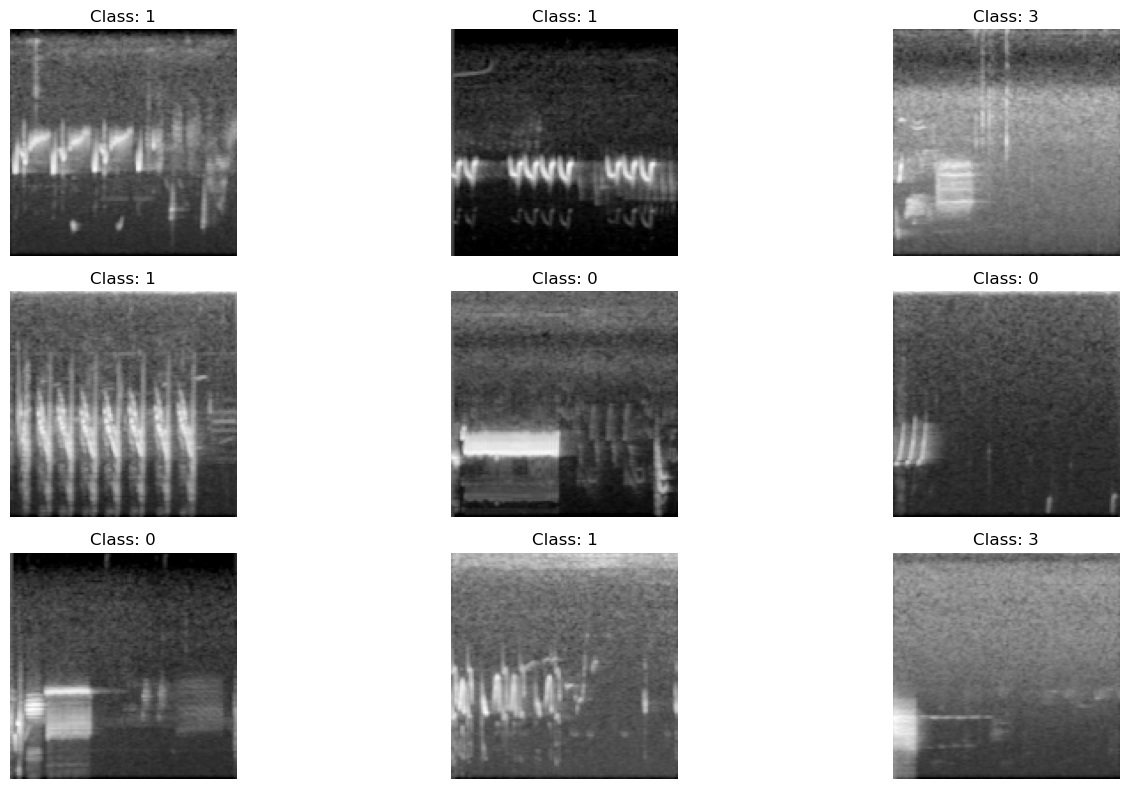

In [13]:
# Visualizing some sample spectrograms
plt.figure(figsize=(15, 8))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[i])
    plt.title(f"Class: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

Let's add data augmentation to improve model generalization. 

In [14]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),   
    layers.RandomZoom(0.1),          
    layers.RandomContrast(0.1),       
])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0273213].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0111891].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0449886].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0212216].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.015092].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.033482].


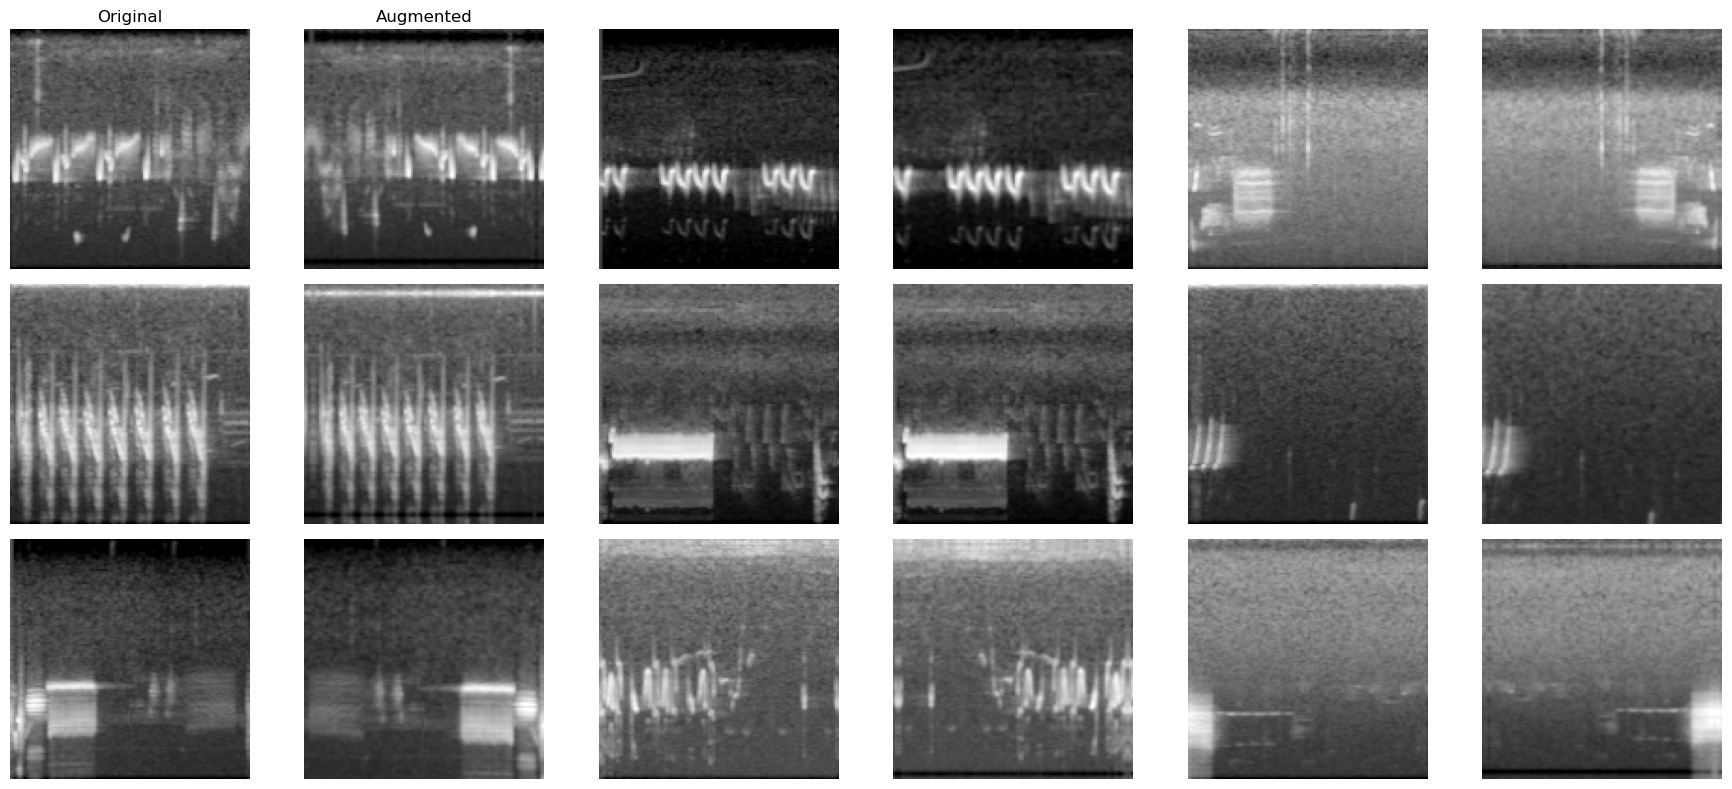

In [15]:
sample_images = X_train[:9]

# Apply augmentation
augmented_images = data_augmentation(tf.convert_to_tensor(sample_images), training=True)

# Plot augmented examples
plt.figure(figsize=(18, 8))
for i in range(9):

    # Original
    plt.subplot(3, 6, i*2 + 1)
    plt.imshow(sample_images[i])
    plt.axis('off')
    if i == 0:
        plt.title("Original")

    # Augmented
    plt.subplot(3, 6, i*2 + 2)
    plt.imshow(augmented_images[i].numpy())
    plt.axis('off')
    if i == 0:
        plt.title("Augmented")

plt.tight_layout()
plt.show()

## 3. Model Architecture

Basic CNN architecture with convolutional layers, pooling, and dense layers. The model consists of four convolutional blocks followed by fully connected layers. AI was utilized to increase accuracy of the model. The model is compiled with the Adam optimizer and categorical cross-entropy loss. The model was tested with multiple different hyperparameters, and the best results were achieved with the following model.

In [16]:

model = models.Sequential([
        layers.InputLayer(input_shape=(128,128,3)),
        # Apply data augmentation
        data_augmentation,
        #First convolutional block
        layers.Conv2D(32, (3,3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        
        # Second convolutional block
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        
        # Third convolutional block
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        
        # Fourth convolutional block
        layers.Conv2D(256, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        
        # Flatten and dense layers
        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax')
    ])
    
model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 126, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │     2,359,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,783,429 (10.62 MB)

 Trainable params: 2,782,469 (10.61 MB)

 Non-trainable params: 960 (3.75 KB)

## 4. Training the Model

Adding EarlyStopping to help reduce overfitting and ModelCheckpoint to save the best version of the model during training. The model is trained for a maximum of 30 epochs with a batch size of 32.

In [17]:
# callbacks
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        'bird_cnn_best_model.keras',
        monitor='val_accuracy',
        save_best_only=True
    )
]

In [18]:
# Training the model
batch_size = 32
epochs = 100

history = model.fit(
    X_train, train_y_cat,
    batch_size=batch_size,
    epochs=epochs,
    validation_data=(X_val, val_y_cat),
    callbacks=callbacks,
    verbose=1
)

Epoch 1/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 86s 569ms/step - accuracy: 0.4064 - loss: 2.2992 - val_accuracy: 0.1740 - val_loss: 3.8779
Epoch 2/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 80s 565ms/step - accuracy: 0.4684 - loss: 1.4050 - val_accuracy: 0.2620 - val_loss: 1.7765
Epoch 3/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 81s 573ms/step - accuracy: 0.4833 - loss: 1.2755 - val_accuracy: 0.3400 - val_loss: 1.4112
Epoch 4/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 81s 574ms/step - accuracy: 0.5267 - loss: 1.1567 - val_accuracy: 0.5640 - val_loss: 0.9670
Epoch 5/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 79s 560ms/step - accuracy: 0.5438 - loss: 1.0638 - val_accuracy: 0.5960 - val_loss: 0.9412
Epoch 6/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 76s 537ms/step - accuracy: 0.6011 - loss: 0.9712 - val_accuracy: 0.6680 - val_loss: 0.8859
Epoch 7/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 75s 535ms/step - accuracy: 0.6444 - loss: 0.8814 - val_accuracy: 0.7480 - val_loss: 0.7358
Epoch 8/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 78s 553ms/step - accuracy: 0.6884 -

In [19]:
test_loss, test_acc = model.evaluate(X_test, test_y_cat, verbose=2)
print(f"Test accuracy: {test_acc:.3f}")
print(f"Test loss: {test_loss:.3f}")

14/14 - 1s - 93ms/step - accuracy: 0.9194 - loss: 0.2568
Test accuracy: 0.919
Test loss: 0.257


Before data augmentation, accuracy and loss measured with the test set were 91.7% and 0.322 respectively.

After implementing data augmentation, accuracy is measured 91.9% and loss is 0.257.

## 5. Evaluation

The relatively high accuracy indicate that the model performs well on unseen data, demonstrating its ability to generalize beyond the training set. The model is capable of accurately classifying bird species based on their songs, making it a valuable tool for ornithological studies and bird conservation efforts.

Below are the training and validation accuracy and loss plots. As we can see, the model shows good convergence without significant overfitting.

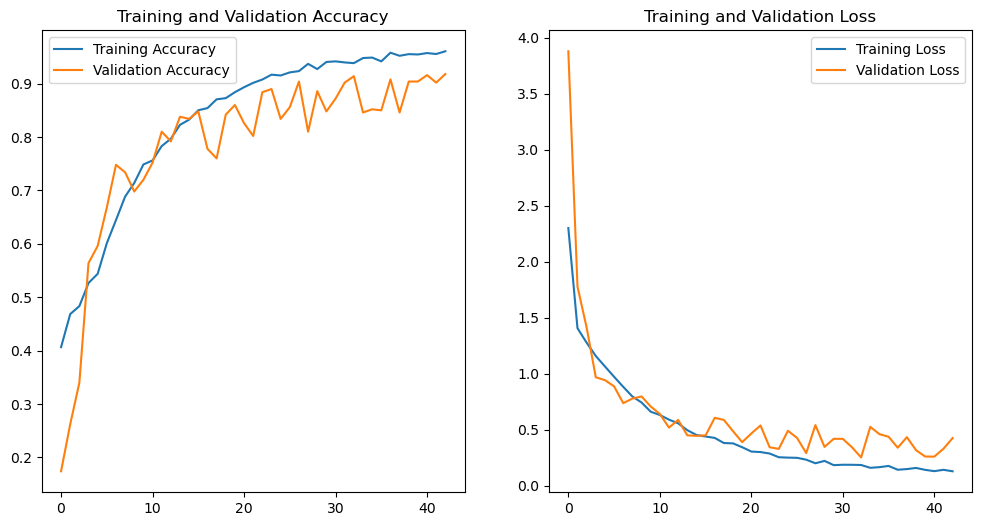

In [20]:
val_accuracy = history.history['val_accuracy']
val_loss = history.history['val_loss']
train_accuracy = history.history['accuracy']
train_loss = history.history['loss']

epochs = range(len(train_accuracy))

# Plot training  and validation accuracy
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(epochs, train_accuracy, label='Training Accuracy')
plt.plot(epochs, val_accuracy, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()

# Plot training and validation loss
plt.subplot(1, 2, 2)
plt.plot(epochs, train_loss, label='Training Loss')
plt.plot(epochs, val_loss, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

The confusion matrix below provides insights into the model's performance across different bird species. It highlights which species are frequently misclassified, allowing for targeted improvements in future iterations of the model. From here, we can identify that most of the misclassifications were Bewick's Wren being classified as American Robin and Northern Cardinal being classified as Song Sparrow.

14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 101ms/step


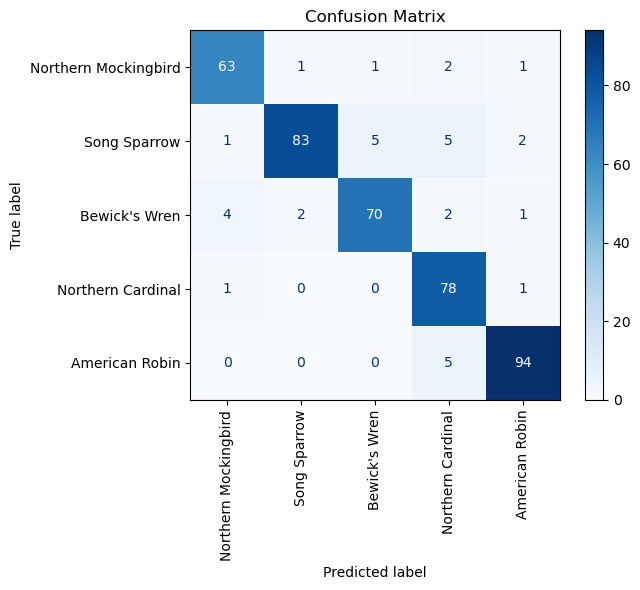

In [21]:
# Confusion Matrix
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
cm = confusion_matrix(y_test, y_pred_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=list(class_mapping.values()))
disp.plot(cmap=plt.cm.Blues, xticks_rotation='vertical')
plt.title('Confusion Matrix')
plt.show()

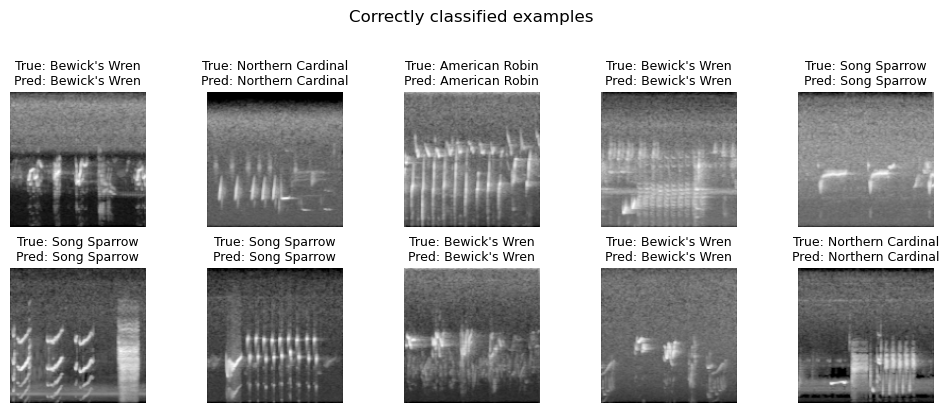

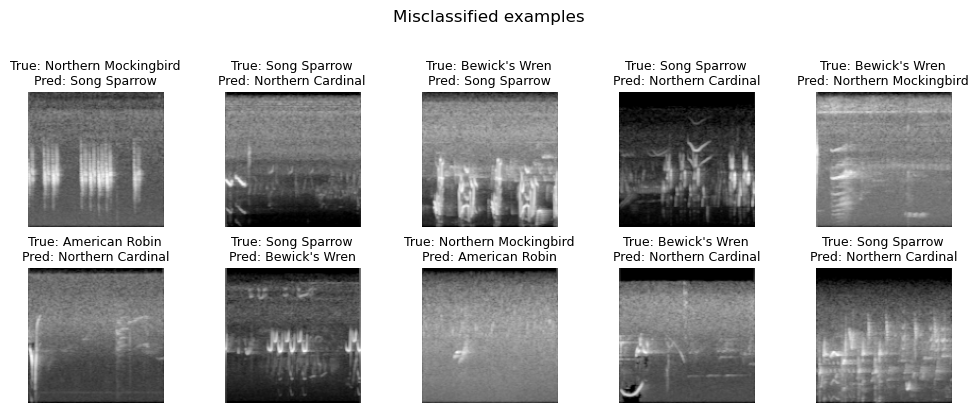

In [24]:
import random

labels = [class_mapping[i] for i in range(num_classes)]
y_true = np.argmax(test_y_cat, axis=1)

def show_examples(idxs, title, n=10):
    cols = 5
    rows = int(np.ceil(n / cols))
    plt.figure(figsize=(cols * 2.0, rows * 2.0))
    plt.suptitle(title, fontsize=12, y=1.02)

    sampled_idxs = random.sample(list(idxs), min(n, len(idxs)))

    for i, idx in enumerate(sampled_idxs):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(X_test[idx]) 
        true_label = labels[y_true[idx]]
        pred_label = labels[y_pred_classes[idx]]
        
        plt.title(f"True: {true_label}\nPred: {pred_label}",
                  fontsize=9, pad=5)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

correct_idx = np.where(y_pred_classes == y_true)[0]
incorrect_idx = np.where(y_pred_classes != y_true)[0]

show_examples(correct_idx, "Correctly classified examples")
show_examples(incorrect_idx, "Misclassified examples")

### Conclusion

The custom CNN model demonstrates strong performance in classifying bird species based on their songs, achieving high accuracy on the test set. The architecture effectively captures relevant features from the spectrograms, and the use of early stopping and model checkpointing helps mitigate overfitting. Future work could explore more data augmentation techniques, hyperparameter tuning, and more complex architectures to further enhance model performance.